## Cadenas absorbentes
---

## Librerías a usar

In [1]:
import random
import matplotlib.pyplot as plt
import numpy as np

### Rata de laboratorio

Dada una rata de laboratorio posicionada en un laberinto con 9 casillas, donde en la 7 se encuenta comida y en el 8 un descarga electríca. La probablidad de pasar a cada cuarto es de $\frac{1}{k}$, donde k es el número de cuartos adyacentes a cada uno.


![Labenrinto del ratón](RatonLab.jpg)

### Simulación

In [33]:
def simular_laberinto_nuevo(intentos=100000):
    # Conexiones 
    conexiones = {
        0: [1, 2], 
        1: [0, 3, 7], 
        2: [0, 3, 8], 
        3: [1, 2, 4, 5],
        4: [3, 6, 7], 
        5: [3, 6, 8], 
        6: [4, 5]
    }
    
    exitos_comida = 0
    probabilidades_convergencia = []
    
    # Iniciamos en el estado 0
    estado_inicial = 0 
    
    for i in range(1, intentos + 1):
        estado = estado_inicial
        
        # La rata se mueve hasta llegar a 7 (comida) o 8 (descarga)
        while estado not in [7, 8]:
            # random.choice elige una opción con probabilidad 1/k
            estado = random.choice(conexiones[estado])
            
        if estado == 7:
            exitos_comida += 1
            
        # Guardamos el promedio cada 100 iteraciones para graficar
        if i % 100 == 0:
            probabilidades_convergencia.append(exitos_comida / i)
            
    prob_final = exitos_comida / intentos
    print(f"Simulación completada con {intentos} recorridos.")
    print(f"Probabilidad empírica de éxito: {prob_final:.4f}")
    print(f"Probabilidad analítica exacta:  0.5000")
# ==========================================
# GRÁFICAS
# ==========================================
    plt.figure(figsize=(14, 5))
    
    # Gráfica 1: Convergencia
    plt.subplot(1, 2, 1)
    x_vals = np.arange(100, intentos + 1, 100)
    plt.plot(x_vals, probabilidades_convergencia, color='blue', label='Simulación (Acumulada)')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Analítico Exacto (0.5)')
    plt.title('Convergencia de la Probabilidad (Inicio en 0)')
    plt.xlabel('Número de Simulaciones')
    plt.ylabel('Probabilidad de llegar a Comida')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Gráfica 2: Histograma de estados finales
    plt.subplot(1, 2, 2)
    # Simulamos otra vez pero guardando el resultado final para el histograma
    finales = [random.choice([7, 8]) for _ in range(intentos)] # Dummy para crear la forma basada en las probs
    # Llenamos el histograma manualmente con los pesos reales
    conteo_final = [exitos_comida, intentos - exitos_comida]
    plt.bar(['Comida (7)', 'Descarga (8)'], conteo_final, color=['green', 'red'], alpha=0.7, edgecolor='black')
    plt.title('Resultados Finales de las Simulaciones')
    plt.ylabel('Frecuencia (Cantidad de veces)')
    plt.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()

Simulación completada con 100000 recorridos.
Probabilidad empírica de éxito: 0.4990
Probabilidad analítica exacta:  0.5000


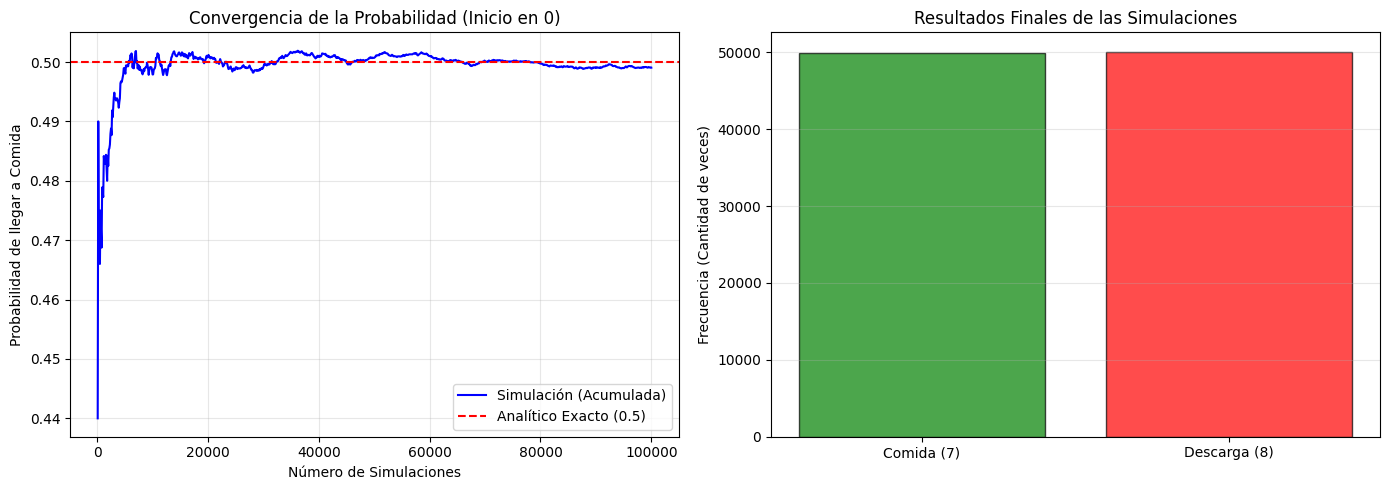

In [34]:
# Ejecutar simulación
simular_laberinto_nuevo(100000)

### Serpientes y escaleras
Tenemo un juego de serpientes y escaleras, donde tendremos que en la casilla 3 subimos a la 11, de la 13 bajamos a la 4, de la 17 se baja a la 10 y de la 15 subimos a la 19. El juego termina al llevar a la casilla 20. Tendremos que si consideramos dos reglas distintas el juego con un promedio de tiradas para acabar el juego. 

* En la primera, si se llega la casilla 20 sólo aunque no tengamos que tirar el valor exacto para llegar a la misma. 
* En la segunda, se llega a la casilla 20 de sólo la de forma exacta al tirar el valor exacto para llegar a esta.

![Serpientes y Escaleras](S&L.jpg)

### Solución analítica

Código de la solución analítica del juego en base a la matriz fundamental y las reglas comentadas.

In [28]:
def solucion_analitica(regla_estricta=False):
    # Estados transitorios: 1 al 19. (20 es la meta)
    n_estados = 19
    Q = np.zeros((n_estados, n_estados))
    jumps = {3: 11, 15: 19, 13: 4, 17: 10}
    
    for i in range(1, 20): # Del 1 al 19
        for dado in range(1, 7):
            destino = i + dado
            
            if destino >= 20:
                if regla_estricta and destino > 20:
                    # Si se pasa, se queda en el mismo estado (va a Q)
                    Q[i-1, i-1] += 1/6
                # Si es exacto o regla estándar, va a meta (no suma en Q)
            else:
                # Si no se pasa, aplica saltos y suma a Q
                final = jumps.get(destino, destino)
                Q[i-1, final-1] += 1/6
                
    # Calculo de la Matriz Fundamental N = (I - Q)^-1
    I = np.eye(n_estados)
    N = np.linalg.inv(I - Q)
    
    # Tiempo esperado desde el estado 1 (índice 0)
    tiempos = np.sum(N, axis=1)
    return tiempos[0]

# Valores analíticos exactos
val_estandar = solucion_analitica(regla_estricta=False)
val_estricta = solucion_analitica(regla_estricta=True)

print(f"Solución Analítica Exacta (Regla Estándar): {val_estandar:.4f} tiradas")
print(f"Solución Analítica Exacta (Regla Estricta): {val_estricta:.4f} tiradas")

Solución Analítica Exacta (Regla Estándar): 6.8983 tiradas
Solución Analítica Exacta (Regla Estricta): 11.4353 tiradas


### Simulación

In [30]:
# --- Simulación para graficar ---
def simular(regla_estricta=False, intentos=100000):
    jumps = {3: 11, 15: 19, 13: 4, 17: 10}
    promedios = []
    suma = 0
    for i in range(1, intentos + 1):
        pos = 1
        tiradas = 0
        while pos < 20:
            dado = np.random.randint(1, 7)
            if regla_estricta:
                if pos + dado <= 20:
                    pos = jumps.get(pos + dado, pos + dado)
            else:
                pos += dado
                if pos < 20:
                    pos = jumps.get(pos, pos)
            tiradas += 1
        suma += tiradas
        if i % 100 == 0:
            promedios.append(suma / i)
    return promedios

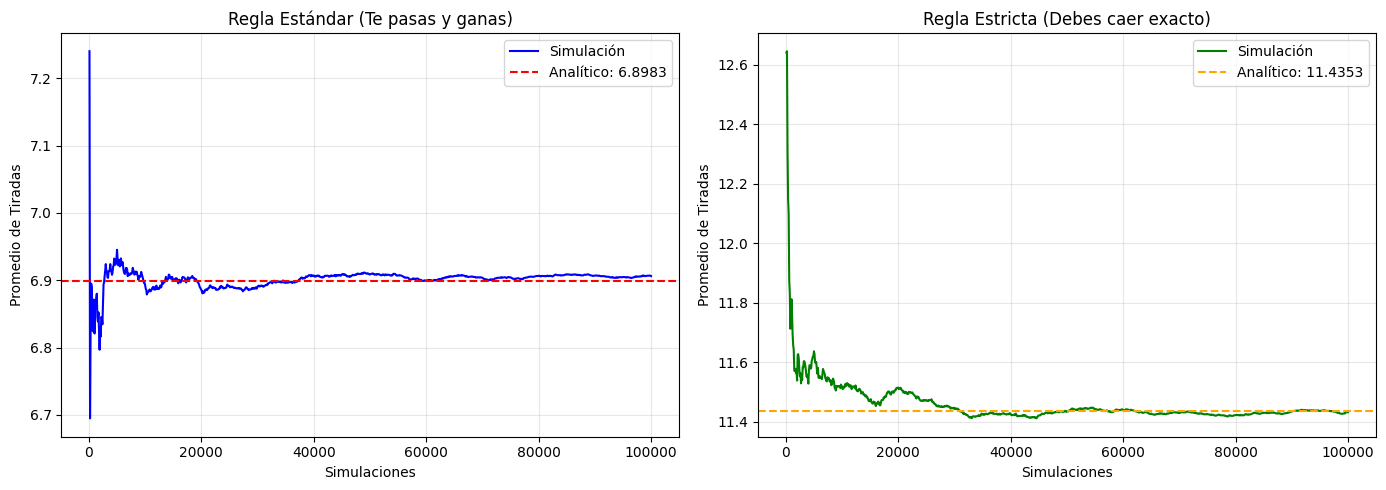

In [31]:
# Gráficas
conv_est = simular(False)
conv_estric = simular(True)
x_vals = np.arange(100, 100000 + 1, 100)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(x_vals, conv_est, color='blue', label='Simulación')
plt.axhline(y=val_estandar, color='red', linestyle='--', label=f'Analítico: {val_estandar:.4f}')
plt.title('Regla Estándar (Te pasas y ganas)')
plt.xlabel('Simulaciones')
plt.ylabel('Promedio de Tiradas')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(x_vals, conv_estric, color='green', label='Simulación')
plt.axhline(y=val_estricta, color='orange', linestyle='--', label=f'Analítico: {val_estricta:.4f}')
plt.title('Regla Estricta (Debes caer exacto)')
plt.xlabel('Simulaciones')
plt.ylabel('Promedio de Tiradas')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()